/var/folders/8q/6sj0nm050xj84zs47gx4m0wm0000gn/T/ipykernel_62857/1346704531.py:8: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(file)


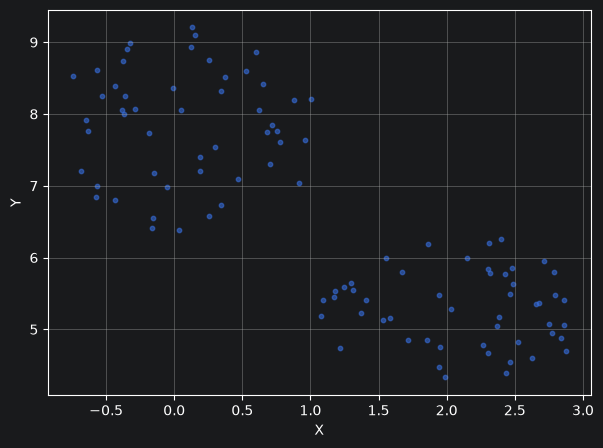

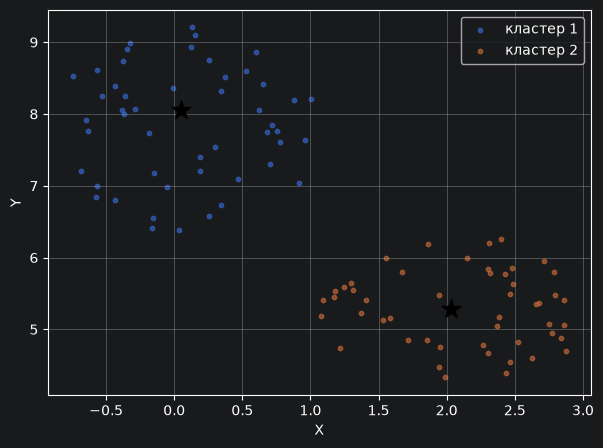

X = 1041.01  Y = 6671.17


/var/folders/8q/6sj0nm050xj84zs47gx4m0wm0000gn/T/ipykernel_62857/1346704531.py:8: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(file)


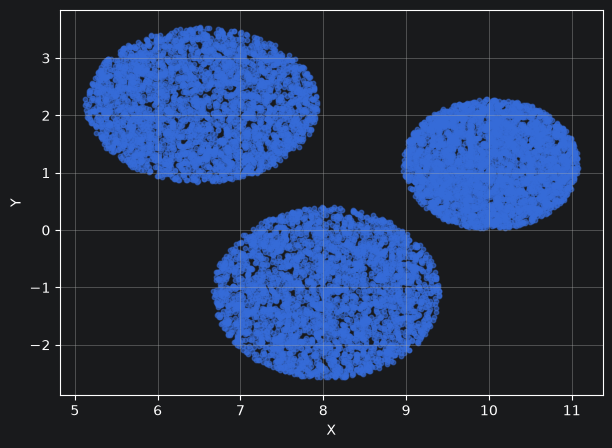

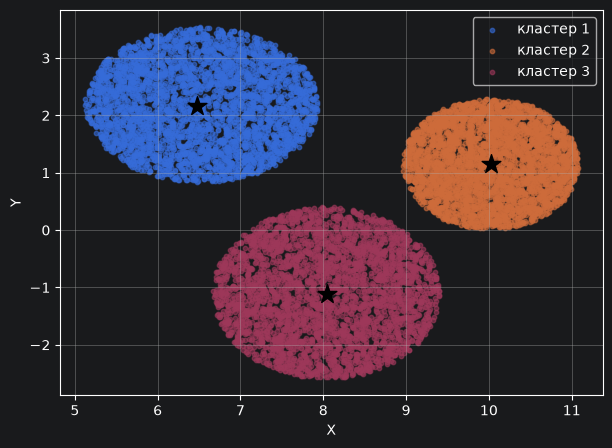

X = 8177.53  Y = 738.42


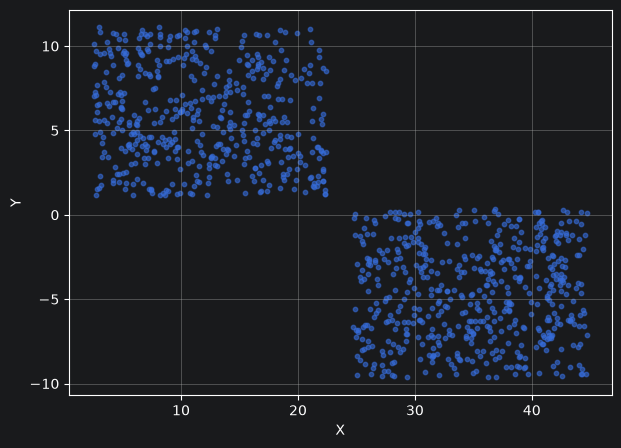

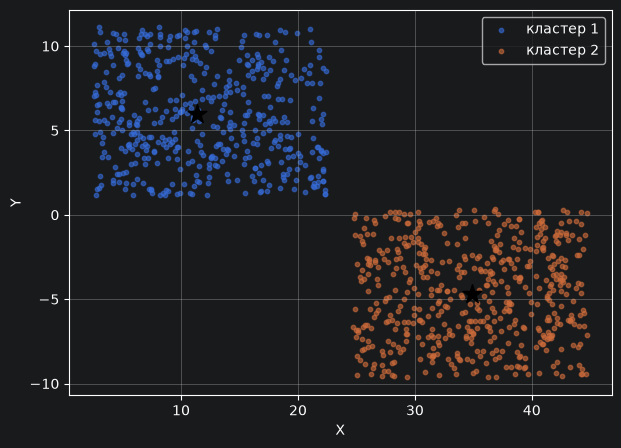

X = 23130.22  Y = 635.34


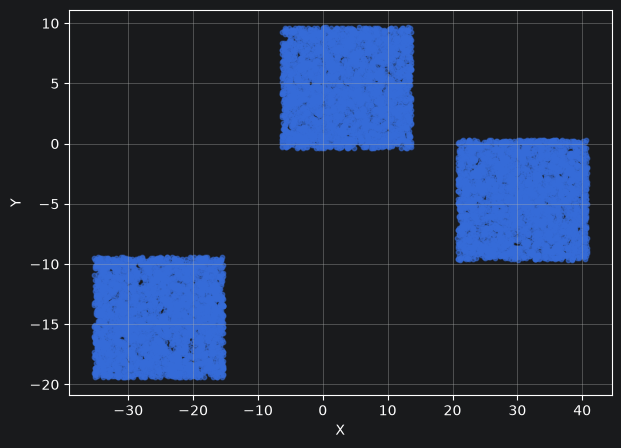

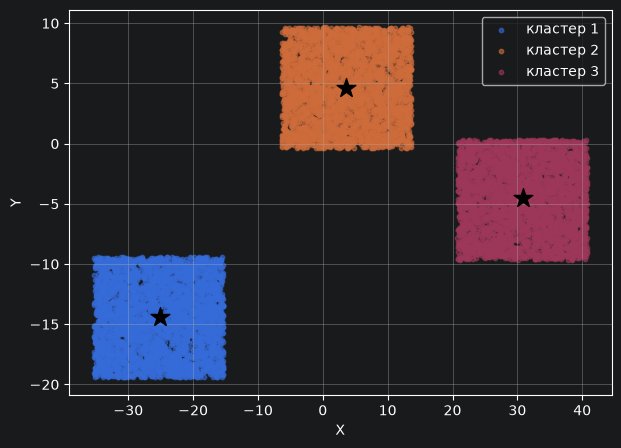

X = 3078.89  Y = -4758.95


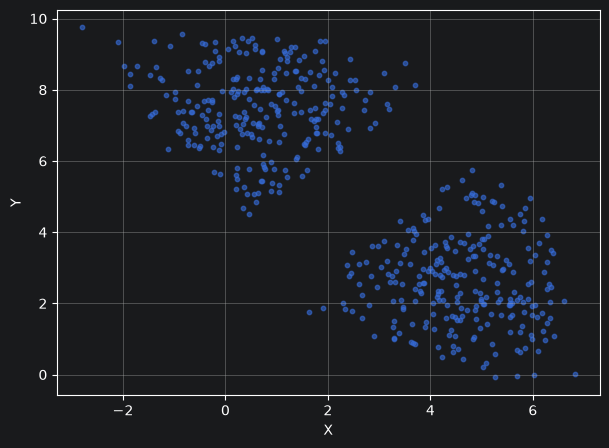

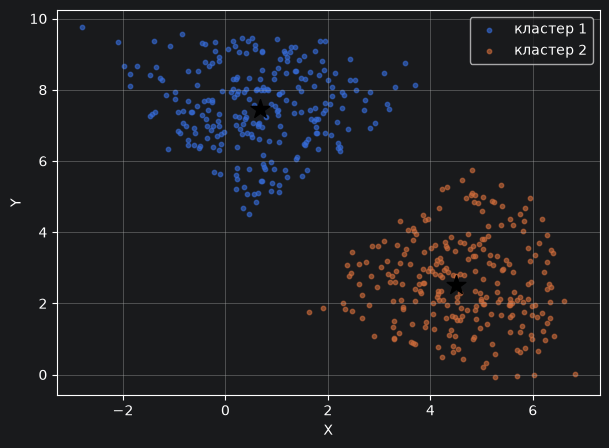

X = 2588.54  Y = 4996.57


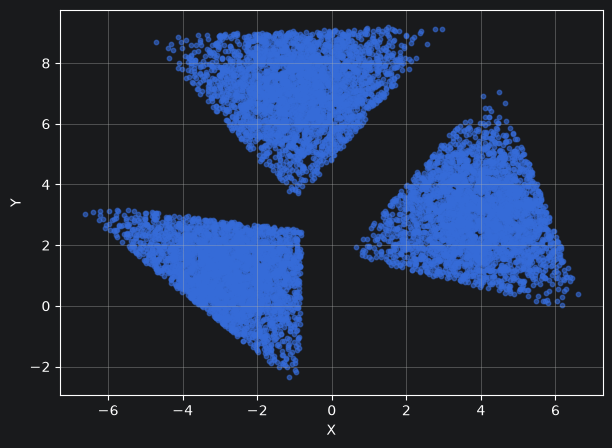

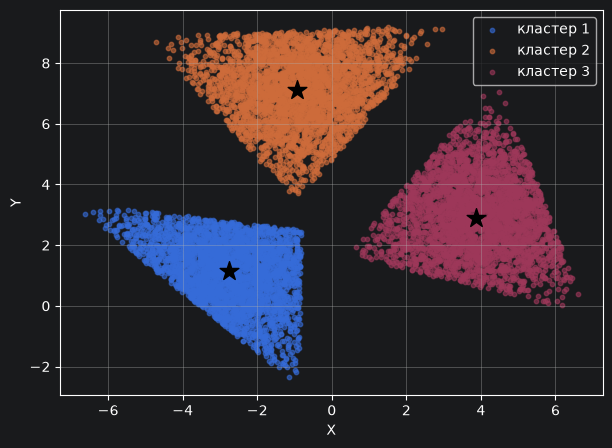

X = 61.65  Y = 3723.36


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
plt.rcParams['figure.figsize'] = (7, 5)
plt.rcParams['axes.grid'] = True
def load(file):
    df = pd.read_excel(file)
    if "X" in df.columns:
        return df[["X", "Y"]].values
    df = pd.read_excel(file, header=None)
    return df.iloc[:, :2].values
def find_med(p, metric="euclidean"):
    D = cdist(p, p, metric=metric)
    return p[np.argmin(D.sum(axis=1))]
def lab(pts, file):
    labels = np.zeros(len(pts), dtype=int)
    if file == "0.xls":
        for i, (x, y) in enumerate(pts):
            labels[i] = 0 if y > 6.3 else 1
    elif file == "1.xls":
        for i, (x, y) in enumerate(pts):
            if x < 8.5 and y > 0.5:
                labels[i] = 0
            elif x > 8.93 and y > 0:
                labels[i] = 1
            else:
                labels[i] = 2
    elif file == "2.xlsx":
        for i, (x, y) in enumerate(pts):
            labels[i] = 0 if x < 23.5 else 1
    elif file == "3.xlsx":
        for i, (x, y) in enumerate(pts):
            if x < -10:
                labels[i] = 0
            elif x < 17:
                labels[i] = 1
            else:
                labels[i] = 2
    elif file == "4.xlsx":
        for i, (x, y) in enumerate(pts):
            labels[i] = 0 if y > x + 2.5 else 1
    elif file == "5.xlsx":
        for i, (x, y) in enumerate(pts):
            if x < 0 and y < 3.4:
                labels[i] = 0
            elif y > x + 3.5:
                labels[i] = 1
            else:
                labels[i] = 2
    return labels
def do(file, n_clusters, metric):
    pts = load(file)
    plt.figure()
    plt.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.6)
    plt.xlabel("X"); plt.ylabel("Y")
    plt.show()
    labels = lab(pts, file)
    plt.figure()
    medss = []
    for i in range(n_clusters):
        cluster = pts[labels == i]
        plt.scatter(cluster[:, 0], cluster[:, 1], s=10, alpha=0.6, label=f"кластер {i+1}")
        med = find_med(cluster, metric)
        medss.append(med)
        plt.scatter(med[0], med[1], s=200, c="black", marker="*", zorder=5)
    plt.xlabel("X"); plt.ylabel("Y")
    plt.legend(); plt.show()

    avg = np.mean(medss, axis=0) * 1000
    print(f"X = {avg[0]:.2f}  Y = {avg[1]:.2f}")
    return avg

avg0 = do("0.xls",  2, "euclidean")
avg1 = do("1.xls",  3, "euclidean")
avg2 = do("2.xlsx", 2, "euclidean")
avg3 = do("3.xlsx", 3, "cityblock")
avg4 = do("4.xlsx", 2, "cityblock")
avg5 = do("5.xlsx", 3, "euclidean")